# 01 — Calidad y EDA de `fact_award_item`

Espacio para explorar, graficar, hipotesis y conclusiones de la Fase 2. 
No modifica `data/processed/` ni reemplaza scripts reproducibles.

Antes de ejecutarlo deben existir:

- `data/processed/fact_award_item/_SUCCESS`
- `data/processed/fact_award/_SUCCESS`
- `artifacts/quality/fact_award_item/_SUCCESS`

Si falta el segundo, ejecute desde la raíz del repositorio:

    python -m src.quality.profile_fact_award_item --overwrite

## Regla financiera

`award_amount` no se carga ni se suma desde `fact_award_item`. Ese monto pertenece a una adjudicación y puede repetirse por cada ítem. La sección monetaria usa `fact_award`, que tiene una fila por adjudicación, y nunca mezcla monedas.


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import pyarrow.dataset as ds
from IPython.display import Markdown, display

ROOT = Path.cwd().resolve()
if not (ROOT / 'data').exists():
    ROOT = ROOT.parent

FACT_DIR = ROOT / 'data' / 'processed' / 'fact_award_item'
FACT_AWARD_DIR = ROOT / 'data' / 'processed' / 'fact_award'
PROFILE_DIR = ROOT / 'artifacts' / 'quality' / 'fact_award_item'

assert (FACT_DIR / '_SUCCESS').is_file(), f'Falta tabla publicada: {FACT_DIR}'
assert (FACT_AWARD_DIR / '_SUCCESS').is_file(), f'Falta tabla publicada: {FACT_AWARD_DIR}'
assert (PROFILE_DIR / '_SUCCESS').is_file(), f'Falta perfil publicado: {PROFILE_DIR}'

print(f'Raíz del proyecto: {ROOT}')


Raíz del proyecto: C:\Users\HP\Desktop\2026-02\DataMining\Proyecto2


## 1. Perfil técnico publicado

Este resumen proviene del perfil reproducible. Sirve para decidir qué explorar; no sustituye la interpretación.


In [2]:
with (PROFILE_DIR / 'profile.json').open(encoding='utf-8') as source:
    profile = json.load(source)

metrics = profile['global_metrics']
duplicates = profile['candidate_key_diagnostics']
profile_summary = pd.DataFrame(
    [
        ('Filas', metrics['rows']),
        ('Procesos distintos', metrics['distinct_processes']),
        ('Adjudicaciones: proceso + award_id', metrics['distinct_awards']),
        ('Proveedores distintos', metrics['distinct_suppliers']),
        ('Entidades distintas', metrics['distinct_entities']),
        ('Fechas de adjudicación ausentes', metrics['award_date_missing']),
        ('Clasificaciones de ítem ausentes', metrics['item_classification_id_missing']),
        ('Duplicados exactos excedentes', duplicates['exact_duplicate_excess_rows']),
    ],
    columns=['métrica', 'valor'],
)
display(profile_summary)

award_date_range = (
    f"**Rango de award_date:** {metrics['min_award_date']} a "
    f"{metrics['max_award_date']}"
)
display(Markdown(award_date_range))


,métrica,valor
0,Filas,137292
1,Procesos distintos,119762
2,Adjudicaciones: proceso + award_id,128395
3,Proveedores distintos,62919
4,Entidades distintas,2967
5,Fechas de adjudicación ausentes,35
6,Clasificaciones de ítem ausentes,18752
7,Duplicados exactos excedentes,0


**Rango de award_date:** 2015-03-19 00:00:00 a 2024-12-26 00:00:00

Un **perfil técnico** es un resumen automático de la tabla: cuántas filas tiene, cuántas entidades distintas hay y si faltan datos importantes.

- Cada fila representa un ítem adjudicado; por eso puede haber más filas que adjudicaciones.
- `Duplicados exactos excedentes = 0` indica que no se repitió una misma fila completa.
- Hay 35 fechas y 18 752 clasificaciones de ítem ausentes. No se borran: se tienen presentes al hacer análisis de tiempo o categoría.


## 2. Cargar una vista ligera para EDA

Se cargan solo columnas necesarias para calidad, tiempo y categorías. Para el volumen actual esta vista cabe en memoria; si el volumen aumenta, las agregaciones deben volver a Spark.


In [3]:
analysis_columns = [
    'source_year',
    'process_ocid',
    'award_id',
    'supplier_id',
    'entity_id',
    'award_date',
    'award_currency',
    'procurement_category',
    'procurement_method',
    'item_classification_id',
]

fact_dataset = ds.dataset(str(FACT_DIR), format='parquet', partitioning='hive')
fact = fact_dataset.to_table(columns=analysis_columns).to_pandas()
fact['award_date'] = pd.to_datetime(fact['award_date'])

fact.head()


,source_year,process_ocid,award_id,supplier_id,entity_id,award_date,award_currency,procurement_category,procurement_method,item_classification_id
0,2023,ocds-dgv273-seacev3-2020-200145-17,614362-20508932350,PE-RUC-20508932350,PE-CONSUCODE-200145,2020-07-10 05:00:00,PEN,services,open,7813180400309809
1,2023,ocds-dgv273-seacev3-657469,657469-20100096936,PE-RUC-20100096936,PE-CONSUCODE-1965,2020-11-10 05:00:00,PEN,goods,open,4223180100134846
2,2023,ocds-dgv273-seacev3-657469,657469-20100096936,PE-RUC-20100096936,PE-CONSUCODE-1965,2020-11-10 05:00:00,PEN,goods,open,4223180200318699
3,2023,ocds-dgv273-seacev3-657469,657469-20100096936,PE-RUC-20100096936,PE-CONSUCODE-1965,2020-11-10 05:00:00,PEN,goods,open,None
4,2023,ocds-dgv273-seacev3-2020-1316-9,618722-20549314253,PE-RUC-20549314253,PE-CONSUCODE-1316,2020-07-14 05:00:00,PEN,goods,open,1510150600286788


Aquí se ven ejemplos reales de las columnas que se usarán después. Una fila no es necesariamente una compra completa: es un **ítem** dentro de una adjudicación.
Curiosidad: una misma `award_id` puede aparecer varias veces porque una adjudicación puede incluir varios ítems. Por eso no se deben sumar montos desde esta tabla.


## 3. Cobertura por archivo, categoría, modalidad y moneda

Estas son frecuencias de filas al grano proceso × adjudicación × proveedor × ítem. Son adecuadas para cobertura y composición; no se interpretan como gasto.


In [4]:
rows_by_source_year = (
    fact.groupby('source_year', dropna=False).size().rename('filas').reset_index()
)
category_counts = (
    fact['procurement_category'].fillna('<MISSING>').value_counts()
    .rename_axis('categoría')
    .reset_index(name='filas')
)
method_counts = (
    fact['procurement_method'].fillna('<MISSING>').value_counts()
    .rename_axis('modalidad')
    .reset_index(name='filas')
)
currency_counts = (
    fact['award_currency'].fillna('<MISSING>').value_counts()
    .rename_axis('moneda')
    .reset_index(name='filas')
)

display(rows_by_source_year)
display(category_counts)
display(method_counts)
display(currency_counts)


,source_year,filas
0,2023,39000
1,2024,98292


,categoría,filas
0,goods,71484
1,services,54714
2,works,11094


,modalidad,filas
0,open,120801
1,direct,15754
2,<MISSING>,734
3,selective,3


,moneda,filas
0,PEN,133961
1,USD,2947
2,EUR,337
3,GBP,44
4,<MISSING>,1
5,JPY,1
6,CAD,1


Todas estas cifras cuentan **filas de ítems**, no dinero ni número final de compras.

- `source_year` indica el archivo de donde vino el dato.
- La categoría, modalidad y moneda permiten ver de qué está compuesta la información.
- Predominan bienes, servicios y la modalidad abierta; PEN es la moneda más frecuente.
- `<MISSING>` significa que el dato no fue informado en la fuente.


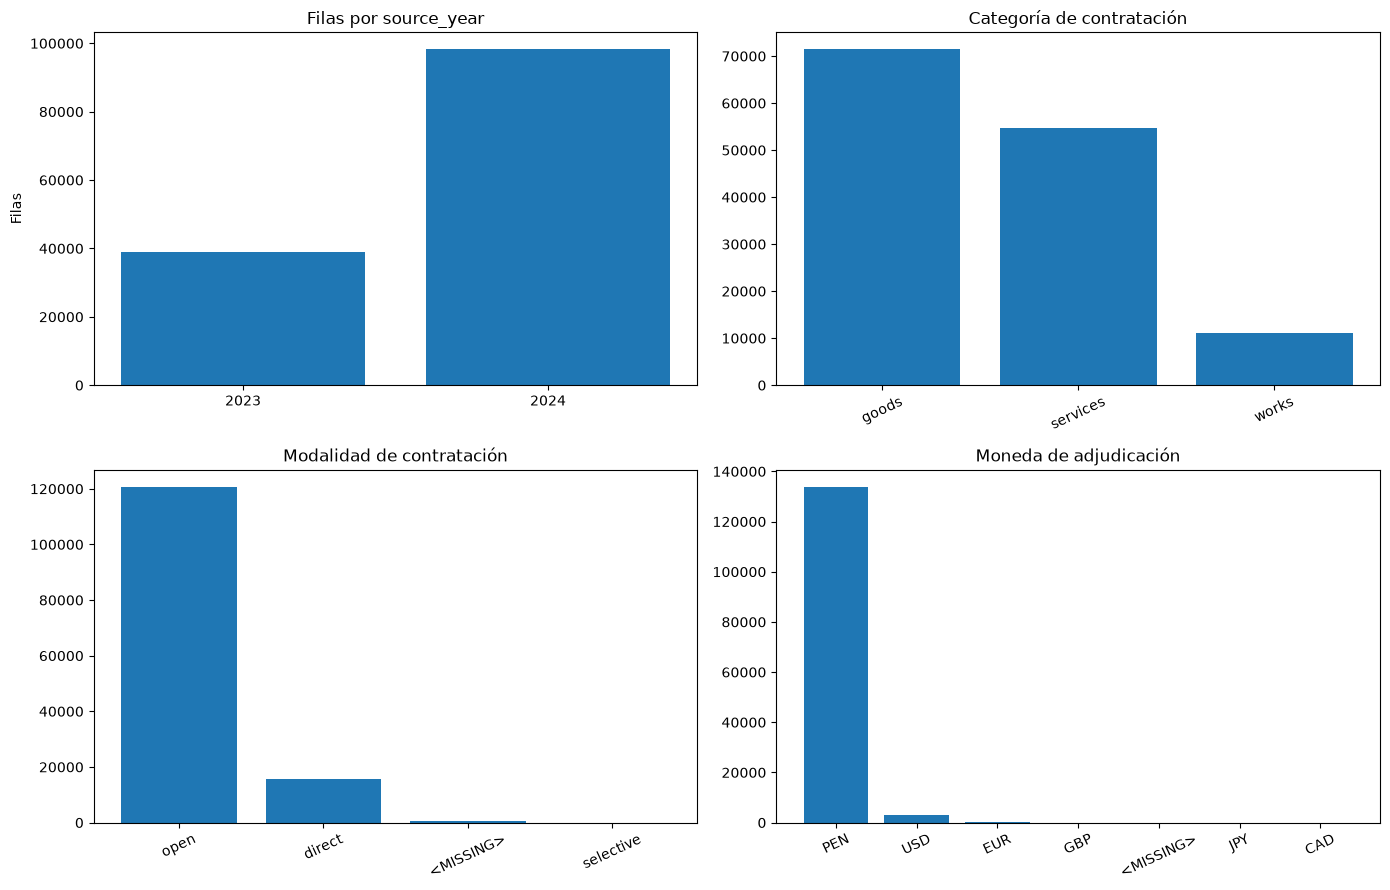

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

axes[0, 0].bar(rows_by_source_year['source_year'].astype(str), rows_by_source_year['filas'])
axes[0, 0].set_title('Filas por source_year')
axes[0, 0].set_ylabel('Filas')

axes[0, 1].bar(category_counts['categoría'], category_counts['filas'])
axes[0, 1].set_title('Categoría de contratación')
axes[0, 1].tick_params(axis='x', rotation=25)

axes[1, 0].bar(method_counts['modalidad'], method_counts['filas'])
axes[1, 0].set_title('Modalidad de contratación')
axes[1, 0].tick_params(axis='x', rotation=25)

axes[1, 1].bar(currency_counts['moneda'], currency_counts['filas'])
axes[1, 1].set_title('Moneda de adjudicación')
axes[1, 1].tick_params(axis='x', rotation=25)

fig.tight_layout()


El gráfico sirve para detectar concentraciones y valores poco frecuentes, por ejemplo modalidades o monedas con muy pocos registros.


## 4. Montos por moneda al grano de adjudicación

`fact_award` tiene una fila por adjudicación. Por ello sus montos pueden agregarse, pero siempre se mantiene `award_currency` como dimensión: una suma entre monedas distintas no tiene interpretación económica.


In [6]:
award_dataset = ds.dataset(str(FACT_AWARD_DIR), format='parquet', partitioning='hive')
award = award_dataset.to_table(
    columns=['source_year', 'award_amount', 'award_currency']
).to_pandas()
award['award_currency'] = award['award_currency'].fillna('<MISSING>')

amount_by_currency = (
    award.groupby('award_currency', dropna=False)
    .agg(adjudicaciones=('award_amount', 'size'), monto=('award_amount', 'sum'))
    .reset_index()
    .sort_values('adjudicaciones', ascending=False)
)
amount_by_source_year_currency = (
    award.groupby(['source_year', 'award_currency'], dropna=False)
    .agg(adjudicaciones=('award_amount', 'size'), monto=('award_amount', 'sum'))
    .reset_index()
    .sort_values(['source_year', 'award_currency'])
)

display(amount_by_currency)
display(amount_by_source_year_currency)


,award_currency,adjudicaciones,monto
5,PEN,125513,87108515998.55
6,USD,2498,1251139562.16
2,EUR,337,41346720.22
3,GBP,44,2880681.50
0,<MISSING>,1,155000.00
1,CAD,1,15248.49
4,JPY,1,40800.00


,source_year,award_currency,adjudicaciones,monto
0,2023,EUR,124,15804360.13
1,2023,GBP,14,389098.51
2,2023,PEN,36051,16880787569.38
3,2023,USD,782,312917750.61
4,2024,<MISSING>,1,155000.00
5,2024,CAD,1,15248.49
6,2024,EUR,213,25542360.09
7,2024,GBP,30,2491582.99
8,2024,JPY,1,40800.00
9,2024,PEN,89462,70227728429.17


Aqui si se usa una fila por adjudicación, por lo que el monto puede agregarse. Los resultados se mantienen separados por moneda.

Aunque PEN concentra la mayor parte de adjudicaciones y monto registrado, **no se debe sumar PEN, USD, EUR u otras monedas**: sus unidades son distintas.


## 5. Tiempo y campos pendientes

`source_year` identifica el archivo descargado; el análisis temporal debe usar `award_date`. Las filas sin fecha se conservan, pero no podrán entrar a una división temporal hasta definir una regla explícita.


In [7]:
missing_by_source_year = (
    fact.assign(
        award_date_missing=fact['award_date'].isna(),
        item_classification_missing=fact['item_classification_id'].isna(),
    )
    .groupby('source_year', dropna=False)[['award_date_missing', 'item_classification_missing']]
    .sum()
    .reset_index()
)
display(missing_by_source_year)

dated = fact.dropna(subset=['award_date']).assign(
    award_year=lambda frame: frame['award_date'].dt.year
)
coverage = pd.crosstab(dated['source_year'], dated['award_year'])
display(coverage)


,source_year,award_date_missing,item_classification_missing
0,2023,10,6316
1,2024,25,12436


award_year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
source_year,,,,,,,,,,
2023,1249,2002,2,10,22,82,262,1730,33545,86
2024,13392,17443,831,61,121,441,1501,11498,11016,41963


La primera tabla cuenta campos faltantes por archivo de origen. La segunda cruza el año del archivo con el año real de `award_date`.

`source_year` no es necesariamente el año de la adjudicación. Un archivo 2024 puede contener adjudicaciones de años anteriores. Para análisis temporal se usa `award_date`, no el nombre del archivo.


## 6. Cobertura de las interacciones anuales

Estas tablas se construyen con Spark. Los metadatos muestran qué parte de cada fuente se pudo agregar y cuántos montos tienen moneda y valor conocidos. Cada fila de proveedor representa una interacción adjudicación–proveedor; no necesariamente una adjudicación distinta si hubiera varios proveedores.


In [8]:
interaction_dirs = {
    'entidad–proveedor': ROOT / 'data' / 'processed' / 'entity_supplier_year',
    'entidad–categoría': ROOT / 'data' / 'processed' / 'entity_category_year',
}
if all((path / '_SUCCESS').is_file() for path in interaction_dirs.values()):
    interaction_profiles = {}
    for name, path in interaction_dirs.items():
        with (path / '_metadata.json').open(encoding='utf-8') as source:
            interaction_profiles[name] = json.load(source)
    run_ids = {profile['run_id'] for profile in interaction_profiles.values()}
    if len(run_ids) != 1:
        raise ValueError('Las tablas pertenecen a corridas distintas; regenere ambas.')
    interaction_summary = []
    for name, profile in interaction_profiles.items():
        metrics = profile['input_metrics']
        interaction_summary.append({
            'tabla': name,
            'filas fuente': metrics['input_rows'],
            'sin fecha': metrics['missing_date_rows'],
            'excluidas': metrics['excluded_rows'],
            'elegibles': metrics['eligible_rows'],
            'con monto y moneda': metrics['eligible_amount_known_rows'],
            'grupos': profile['output_metrics']['output_rows'],
        })
    display(pd.DataFrame(interaction_summary))
else:
    print('Interacciones no publicadas: python -m src.features.build_interactions')


,tabla,filas fuente,sin fecha,excluidas,elegibles,con monto y moneda,grupos
0,entidad–proveedor,128395,35,35,128360,128360,108924
1,entidad–categoría,128395,35,35,128360,128360,21744


Estas tablas resumen las interacciones que alimentarán análisis posteriores.

- **Elegibles**: filas con fecha, que sí pueden ubicarse en el tiempo.
- **Excluidas**: filas sin fecha, que se conservan pero no entran a cortes temporales.
- **Grupos**: combinaciones finales que se forman al agrupar entidad–proveedor o entidad–categoría.

No mide calidad de una recomendación todavía; solo confirma cuánto material existe para construirla.


## 7. Conclusiones iniciales y siguientes decisiones

Complete esta sección al interpretar los gráficos. Mantenga separadas las observaciones de las decisiones metodológicas.

- **Observación confirmada:** no hay duplicados exactos ni repeticiones de la llave candidata actual.
- **Observación confirmada:** existen varias monedas; no se sumarán montos sin conversión documentada.
- **Observación confirmada:** existen ítems sin clasificación; todavía no se eliminan.
- **Decisión confirmada:** `fact_award` es la tabla para métricas monetarias por moneda; `fact_award_item` se conserva para detalle por ítem.
- **Decisión confirmada:** `fact_award_supplier` conserva una fila por adjudicación–proveedor. En la corrida actual hay un proveedor por adjudicación; si cambia, no se asignarán montos por proveedor sin una regla explícita.
- **Decisión para las primeras interacciones anuales:** excluir las filas sin `award_date`, contabilizarlas en los metadatos y no imputar su fecha. En la corrida de referencia hay 35 filas de detalle sin fecha; otras corridas pueden variar. Esta decisión no elimina las filas de las tablas fuente y cada modelo deberá revisar sus propias exclusiones.

Al cerrar el cuaderno, trasladar decisiones estables a `docs/README_Estrategico.md` y `docs/ContratoDatos.md`.
